# LeetCode #150: Evaluate Reverse Polish Notation

https://leetcode.com/problems/evaluate-reverse-polish-notation/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Stack-based ★ | O(n) | O(n) |

## Understanding the Methods
### Brute Force
No simpler approach exists; RPN inherently requires stack-based evaluation to maintain operator precedence.

### Optimal: Stack-based ★
Iterate through tokens. If the token is a number, push it onto the stack. If it's an operator (+, -, *, /), pop two operands, apply the operator, and push the result. The final answer is the single remaining value on the stack. Division truncates toward zero (use integer division with sign handling).

## Solutions
### C#

In [ ]:
public class Solution {
    public int EvalRPN(string[] tokens) {
        var stack = new Stack<long>();
        foreach (var token in tokens) {
            if (token == "+" || token == "-" || token == "*" || token == "/") {
                long b = stack.Pop(), a = stack.Pop();
                stack.Push(token switch {
                    "+" => a + b,
                    "-" => a - b,
                    "*" => a * b,
                    _ => (long)(a / b)
                });
            } else {
                stack.Push(long.Parse(token));
            }
        }
        return (int)stack.Pop();
    }
}

### Python

In [ ]:
from typing import List
import math

class Solution:
    def evalRPN(self, tokens: List[str]) -> int:
        stack = []
        ops = {
            '+': lambda a, b: a + b,
            '-': lambda a, b: a - b,
            '*': lambda a, b: a * b,
            '/': lambda a, b: math.trunc(a / b)
        }
        for token in tokens:
            if token in ops:
                b, a = stack.pop(), stack.pop()
                stack.append(ops[token](a, b))
            else:
                stack.append(int(token))
        return stack[-1]

### Go

In [ ]:
package main

import (
    "fmt"
    "strconv"
)

func evalRPN(tokens []string) int {
    stack := []int{}
    for _, t := range tokens {
        switch t {
        case "+", "-", "*", "/":
            n := len(stack)
            a, b := stack[n-2], stack[n-1]
            stack = stack[:n-2]
            switch t {
            case "+":
                stack = append(stack, a+b)
            case "-":
                stack = append(stack, a-b)
            case "*":
                stack = append(stack, a*b)
            case "/":
                stack = append(stack, a/b)
            }
        default:
            n, _ := strconv.Atoi(t)
            stack = append(stack, n)
        }
    }
    return stack[0]
}

func main() {
    fmt.Println(evalRPN([]string{"2","1","+","3","*"})) // 9
}

### Rust

In [ ]:
pub struct Solution;

impl Solution {
    pub fn eval_rpn(tokens: Vec<String>) -> i32 {
        let mut stack: Vec<i64> = Vec::new();
        for token in &tokens {
            match token.as_str() {
                "+" | "-" | "*" | "/" => {
                    let b = stack.pop().unwrap();
                    let a = stack.pop().unwrap();
                    let res = match token.as_str() {
                        "+" => a + b,
                        "-" => a - b,
                        "*" => a * b,
                        _ => a / b,
                    };
                    stack.push(res);
                }
                _ => stack.push(token.parse::<i64>().unwrap()),
            }
        }
        stack[0] as i32
    }
}

## Example Scenarios

### 1. Common Case — Nested Operations
**Input:** `tokens = ["2","1","+","3","*"]`

Push $2,1$; `+` pops both and pushes $3$; push $3$; `*` pops both and pushes $9$. Result $(2+1)\times3=9$.

### 2. Slightly Complex — Division
**Input:** `tokens = ["4","13","5","/","+"]`

`/` pops $5,13$ and pushes $13/5=2$ (truncated); `+` then pops $2,4$ and pushes $6$. Result $4+(13/5)=6$.

### 3. Edge Case: Time Factor — Long Expression
**Input:** `tokens = ["10","6","9","3","+","-11","*","/","*","17","+","5","+"]`

Thirteen tokens processed in a single $O(n)$ pass; the stack rises and falls as operators consume operands. Result $22$.

### 4. Edge Case: Space Factor — Single Number
**Input:** `tokens = ["3"]`

One operand is pushed and never combined; it is the final value. Result $3$. Stack never grows beyond one element.

### 5. Almost-Impossible but Plausible — Negative Truncation
**Input:** `tokens = ["-3","-2","/"]`

`/` pops $-2,-3$ and computes $-3/-2=1.5$, truncated **toward zero** to $1$ (not floored to $1$). Result $1$.


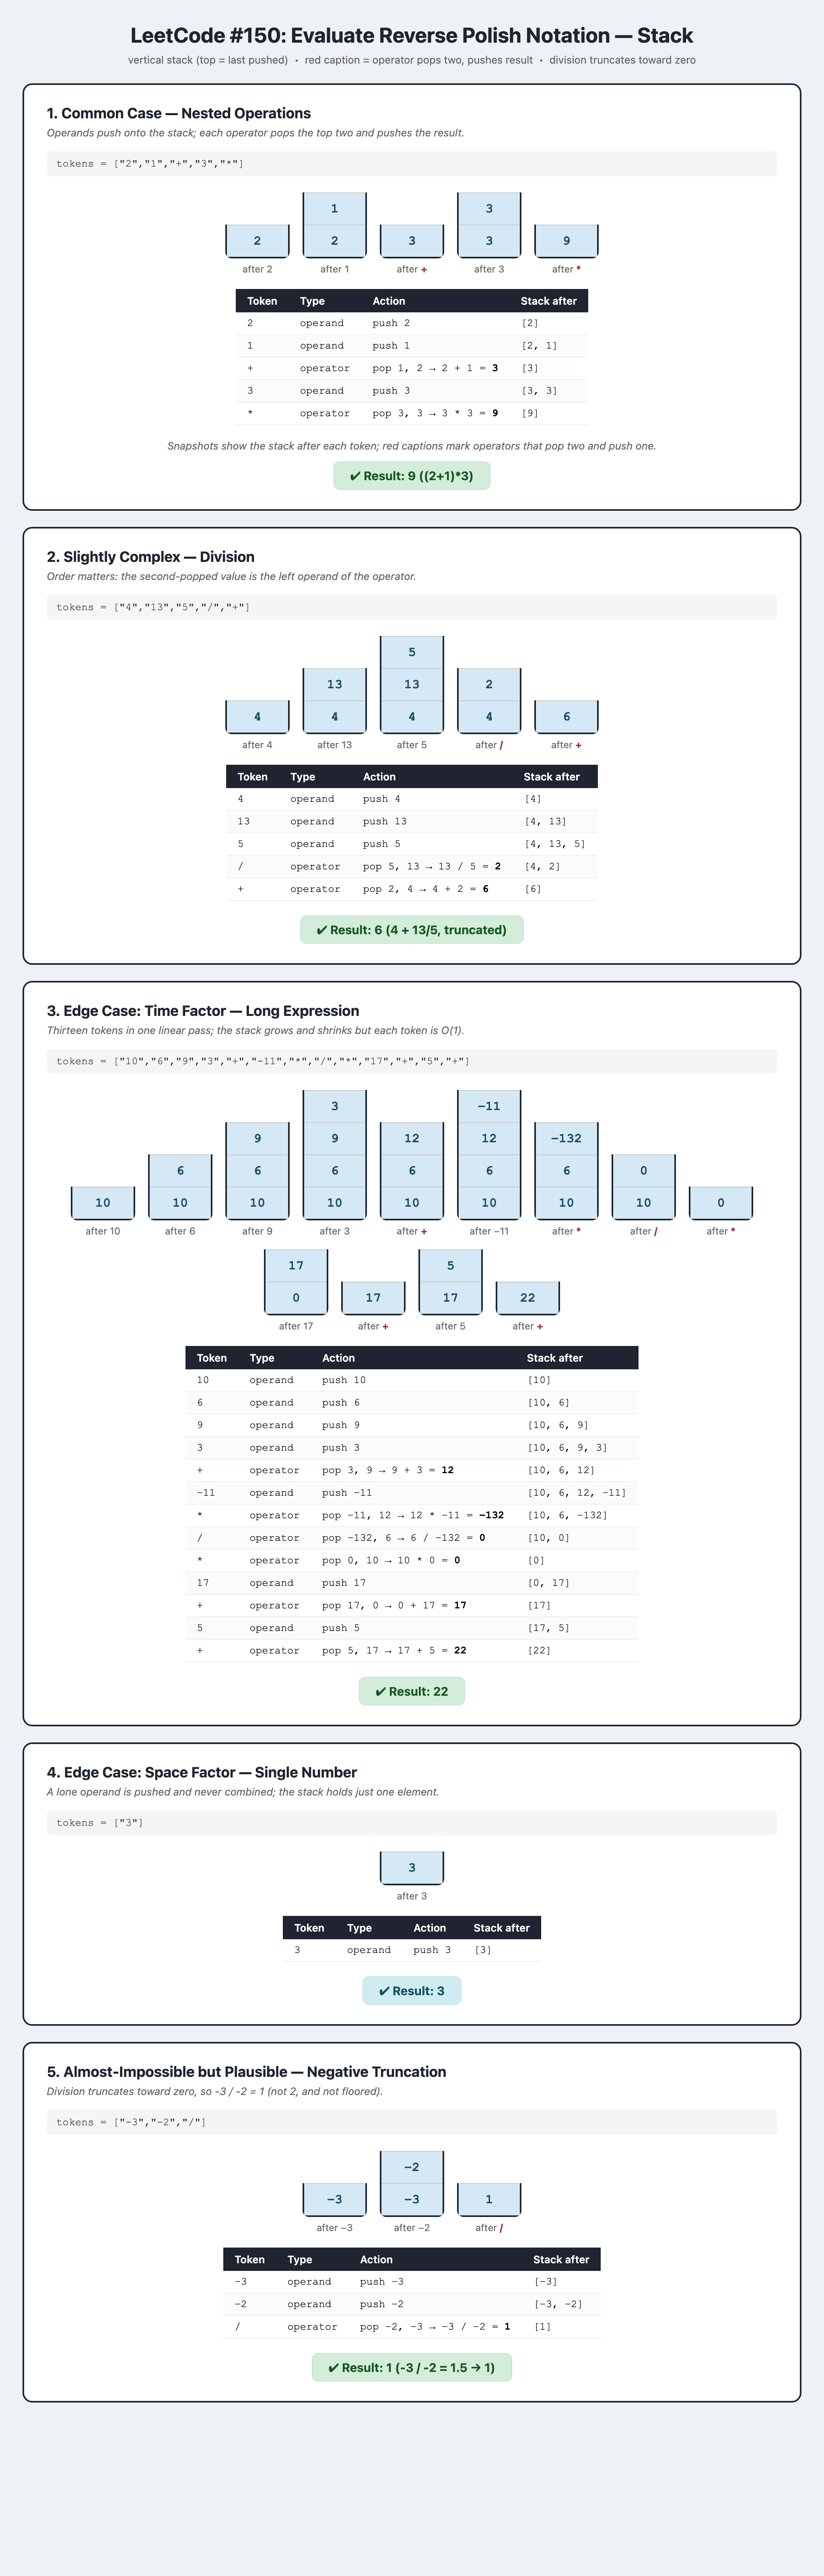